## Residual Forecasting



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from statsmodels.tsa.seasonal import STL
%matplotlib inline
from classes.metrics.hurst import Hurst
ehc = pd.read_excel("data/Dados Demanda Ciclo Otto 8-3009.xlsx")
ehc['Unnamed: 0'] = pd.to_datetime(ehc['Unnamed: 0'])
ehc = ehc[['Unnamed: 0', 'Demanda Etanol Hidratado (m3)']].rename(columns={'Unnamed: 0': 'Data'})
ehc.set_index('Data', inplace=True)

/home/arick/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-efuwtqjp because there was an issue with the default path (/home/arick/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


/tmp/ipykernel_45/158606152.py:11: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ehc.set_index('Data', inplace=True)


### 1. Regressão da média (treino 80%) e projeção para 10 anos (120 meses)

In [2]:
# Transformação log e divisão 80% treino / 20% teste
ehc['log_demanda'] = np.log(ehc['Demanda Etanol Hidratado (m3)'])

n_train = int(len(ehc) * 0.8)
train = ehc.iloc[:n_train].copy()
test = ehc.iloc[n_train:].copy()

# Regressão linear sobre a média de cada bloco de 32 meses (ajustada APENAS no treino)
BLOCO = 32
train['ciclo_32m'] = np.arange(len(train)) // BLOCO
medias_train = train.groupby('ciclo_32m')['log_demanda'].mean()

a, b = np.polyfit(medias_train.index, medias_train.values, 1)
train['regressao_media'] = a * train['ciclo_32m'] + b

# Projeção da regressão da média para os próximos 10 anos (120 meses após o fim do treino)
HORIZONTE_10A = 120
datas_futuras = pd.date_range(
    start=train.index[-1] + pd.offsets.MonthBegin(1),
    periods=HORIZONTE_10A,
    freq='MS',
)
ciclos_futuros = np.arange(n_train, n_train + HORIZONTE_10A) // BLOCO
projecao_10_anos = pd.DataFrame(
    {
        'ciclo_32m': ciclos_futuros,
        'regressao_media_log': a * ciclos_futuros + b,
        'regressao_media_m3': np.exp(a * ciclos_futuros + b),
    },
    index=datas_futuras,
)
projecao_10_anos.index.name = 'Data'

print(f"Total: {len(ehc)} meses | Treino (80%): {len(train)} meses ({train.index[0].strftime('%Y-%m')} a {train.index[-1].strftime('%Y-%m')})")
print(f"Teste (20%): {len(test)} meses ({test.index[0].strftime('%Y-%m')} a {test.index[-1].strftime('%Y-%m')})")
print(f"Coeficientes da regressão (bloco {BLOCO}m): a = {a:.4f}, b = {b:.4f}")
print(f"Projeção armazenada em `projecao_10_anos`: {len(projecao_10_anos)} meses ({projecao_10_anos.index[0].strftime('%Y-%m')} a {projecao_10_anos.index[-1].strftime('%Y-%m')})")
projecao_10_anos.head()

Total: 171 meses | Treino (80%): 136 meses (2010-01 a 2021-04)
Teste (20%): 35 meses (2021-05 a 2024-03)
Coeficientes da regressão (bloco 32m): a = 0.1348, b = 13.8681
Projeção armazenada em `projecao_10_anos`: 120 meses (2021-05 a 2031-04)


,ciclo_32m,regressao_media_log,regressao_media_m3
Data,,,
2021-05-01,4,14.407335,1.807283e+06
2021-06-01,4,14.407335,1.807283e+06
2021-07-01,4,14.407335,1.807283e+06
2021-08-01,4,14.407335,1.807283e+06
2021-09-01,4,14.407335,1.807283e+06


### 2. Resíduo no treino (`log_demanda - regressao_media`) e visualização

Resíduo no treino -> média: 0.0082 | desvio padrão: 0.2090 | min: -0.7350 | max: 0.4367


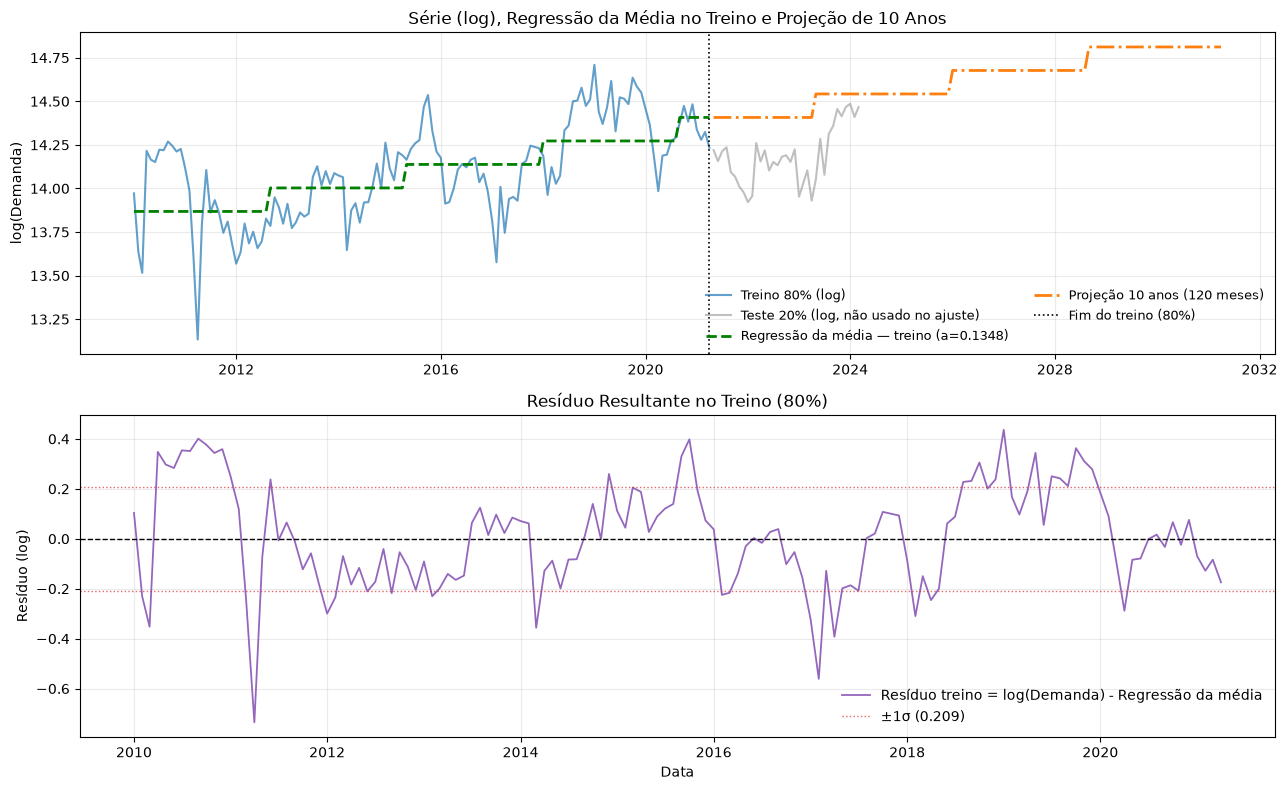

In [3]:
# Subtrai a regressão da média do trecho de treino (80%)
residuo_train = train['log_demanda'] - train['regressao_media']
train['residuo'] = residuo_train

print(f"Resíduo no treino -> média: {residuo_train.mean():.4f} | desvio padrão: {residuo_train.std():.4f} | min: {residuo_train.min():.4f} | max: {residuo_train.max():.4f}")

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

# Gráfico 1: Série (log), regressão da média no treino e projeção de 10 anos
axes[0].plot(train.index, train['log_demanda'], color='tab:blue', alpha=0.7, label='Treino 80% (log)')
axes[0].plot(test.index, test['log_demanda'], color='gray', alpha=0.5, label='Teste 20% (log, não usado no ajuste)')
axes[0].plot(train.index, train['regressao_media'], 'g--', lw=2, label=f'Regressão da média — treino (a={a:.4f})')
axes[0].plot(projecao_10_anos.index, projecao_10_anos['regressao_media_log'],
             color='tab:orange', ls='-.', lw=2, label='Projeção 10 anos (120 meses)')
axes[0].axvline(train.index[-1], color='black', ls=':', lw=1.2, label='Fim do treino (80%)')
axes[0].set_title('Série (log), Regressão da Média no Treino e Projeção de 10 Anos')
axes[0].set_ylabel('log(Demanda)')
axes[0].legend(frameon=False, ncol=2, fontsize=9)
axes[0].grid(alpha=0.25)

# Gráfico 2: Resíduo resultante no treino (80%)
axes[1].plot(train.index, residuo_train, color='tab:purple', lw=1.3, label='Resíduo treino = log(Demanda) - Regressão da média')
axes[1].axhline(0, color='black', ls='--', lw=1.0)
axes[1].axhline(residuo_train.std(), color='tab:red', ls=':', lw=1.0, alpha=0.7, label=f'±1σ ({residuo_train.std():.3f})')
axes[1].axhline(-residuo_train.std(), color='tab:red', ls=':', lw=1.0, alpha=0.7)
axes[1].set_title('Resíduo Resultante no Treino (80%)')
axes[1].set_ylabel('Resíduo (log)')
axes[1].set_xlabel('Data')
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

Janelas de treino: 101 | Loss final (MSE norm): 0.3963
Resíduo previsto: 120 meses (2021-05 a 2031-04)


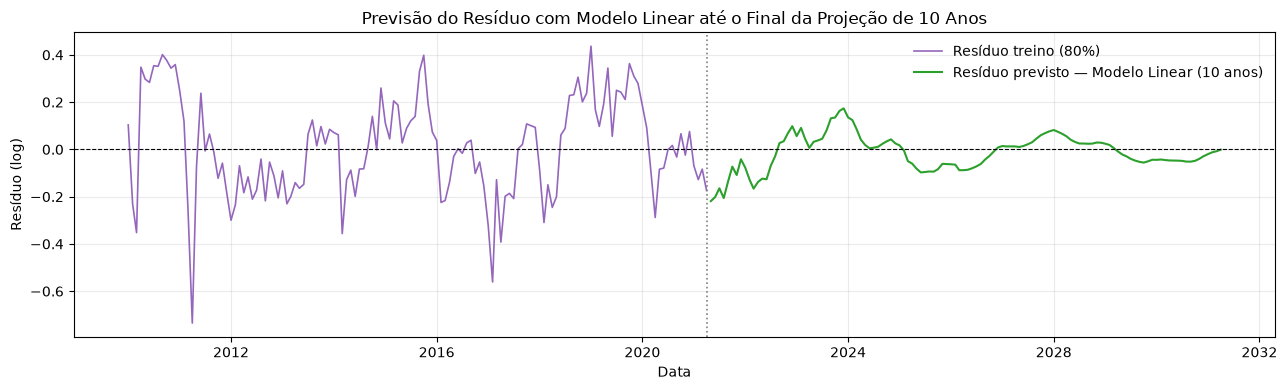

In [4]:
# 1) Previsão do resíduo com modelo linear (PyTorch) até o final da projeção de 10 anos (120 meses)
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

LOOKBACK = 24     # janela de entrada (24 meses)
H_BLOCO = 12      # bloco previsto por vez (12 meses) -> 10 blocos = 120 meses

s_tr = residuo_train.values.astype(np.float32)
mu_r, std_r = s_tr.mean(), s_tr.std() + 1e-8
s_norm = (s_tr - mu_r) / std_r

# Monta janelas de treino (L -> H_BLOCO) apenas no resíduo de treino
X_tr, Y_tr = [], []
for i in range(len(s_norm) - LOOKBACK - H_BLOCO + 1):
    X_tr.append(s_norm[i : i + LOOKBACK])
    Y_tr.append(s_norm[i + LOOKBACK : i + LOOKBACK + H_BLOCO])

X_tr = torch.tensor(np.array(X_tr), dtype=torch.float32)
Y_tr = torch.tensor(np.array(Y_tr), dtype=torch.float32)

# Modelo linear puro (L -> H_BLOCO) com regularização L2 para estabilidade no longo prazo
modelo_linear = nn.Linear(LOOKBACK, H_BLOCO)
opt = torch.optim.Adam(modelo_linear.parameters(), lr=1e-2, weight_decay=1e-2)
loss_fn = nn.MSELoss()

modelo_linear.train()
for _ in range(500):
    opt.zero_grad()
    loss = loss_fn(modelo_linear(X_tr), Y_tr)
    loss.backward()
    opt.step()

# Previsão em blocos de 12 meses até completar todos os 120 meses de `projecao_10_anos` (sem ver o teste)
modelo_linear.eval()
n_passos = len(projecao_10_anos)
janela = s_norm[-LOOKBACK:].copy()
preds_norm = []

with torch.no_grad():
    while len(preds_norm) < n_passos:
        x_in = torch.tensor(janela, dtype=torch.float32).unsqueeze(0)
        y_out = modelo_linear(x_in).squeeze(0).numpy()
        preds_norm.extend(y_out.tolist())
        janela = np.concatenate([janela[H_BLOCO:], y_out])

preds_res = np.array(preds_norm[:n_passos]) * std_r + mu_r
residuo_previsto = pd.Series(preds_res, index=projecao_10_anos.index, name='residuo_previsto')

print(f"Janelas de treino: {len(X_tr)} | Loss final (MSE norm): {loss.item():.4f}")
print(f"Resíduo previsto: {len(residuo_previsto)} meses ({residuo_previsto.index[0].strftime('%Y-%m')} a {residuo_previsto.index[-1].strftime('%Y-%m')})")

plt.figure(figsize=(13, 4))
plt.plot(residuo_train.index, residuo_train, color='tab:purple', lw=1.2, label='Resíduo treino (80%)')
plt.plot(residuo_previsto.index, residuo_previsto, color='tab:green', lw=1.5, label='Resíduo previsto — Modelo Linear (10 anos)')
plt.axhline(0, color='black', ls='--', lw=0.8)
plt.axvline(residuo_train.index[-1], color='gray', ls=':', lw=1.2)
plt.title('Previsão do Resíduo com Modelo Linear até o Final da Projeção de 10 Anos')
plt.ylabel('Resíduo (log)')
plt.xlabel('Data')
plt.legend(frameon=False)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Métricas no período de teste (35 meses: 2021-05 a 2024-03):
  MAE  : 430,973.72 m³
  RMSE : 488,742.71 m³
  MAPE : 30.78%


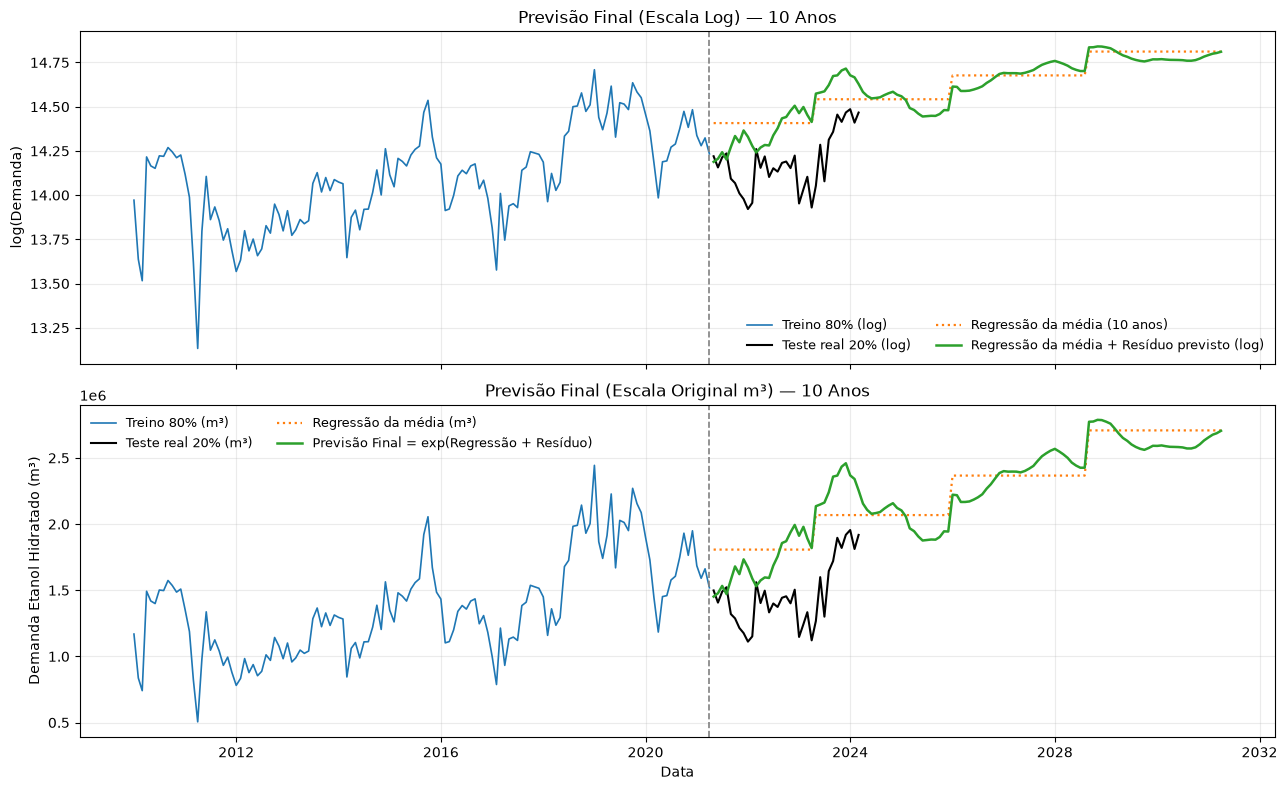

In [5]:
# 2) Soma do resíduo previsto com a regressão da média projetada
previsao_final = pd.DataFrame(
    {
        'regressao_media_log': projecao_10_anos['regressao_media_log'],
        'residuo_previsto': residuo_previsto,
        'previsao_log': projecao_10_anos['regressao_media_log'] + residuo_previsto,
    },
    index=projecao_10_anos.index,
)
previsao_final['previsao_m3'] = np.exp(previsao_final['previsao_log'])

# Avaliação no trecho de teste (20%, nunca visto pelo modelo)
pred_teste_m3 = previsao_final.loc[test.index, 'previsao_m3']
real_teste_m3 = test['Demanda Etanol Hidratado (m3)']
err = pred_teste_m3 - real_teste_m3

print(f"Métricas no período de teste ({len(test)} meses: {test.index[0].strftime('%Y-%m')} a {test.index[-1].strftime('%Y-%m')}):")
print(f"  MAE  : {np.mean(np.abs(err)):,.2f} m³")
print(f"  RMSE : {np.sqrt(np.mean(err ** 2)):,.2f} m³")
print(f"  MAPE : {np.mean(np.abs(err) / np.abs(real_teste_m3)) * 100:.2f}%")

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Escala log
axes[0].plot(train.index, train['log_demanda'], color='tab:blue', lw=1.2, label='Treino 80% (log)')
axes[0].plot(test.index, test['log_demanda'], color='black', lw=1.5, label='Teste real 20% (log)')
axes[0].plot(previsao_final.index, previsao_final['regressao_media_log'],
             color='tab:orange', ls=':', lw=1.6, label='Regressão da média (10 anos)')
axes[0].plot(previsao_final.index, previsao_final['previsao_log'],
             color='tab:green', lw=1.8, label='Regressão da média + Resíduo previsto (log)')
axes[0].axvline(train.index[-1], color='gray', ls='--', lw=1.2)
axes[0].set_title('Previsão Final (Escala Log) — 10 Anos')
axes[0].set_ylabel('log(Demanda)')
axes[0].legend(frameon=False, ncol=2, fontsize=9)
axes[0].grid(alpha=0.25)

# Escala original (m³)
axes[1].plot(train.index, train['Demanda Etanol Hidratado (m3)'], color='tab:blue', lw=1.2, label='Treino 80% (m³)')
axes[1].plot(test.index, real_teste_m3, color='black', lw=1.5, label='Teste real 20% (m³)')
axes[1].plot(previsao_final.index, np.exp(previsao_final['regressao_media_log']),
             color='tab:orange', ls=':', lw=1.6, label='Regressão da média (m³)')
axes[1].plot(previsao_final.index, previsao_final['previsao_m3'],
             color='tab:green', lw=1.8, label='Previsão Final = exp(Regressão + Resíduo)')
axes[1].axvline(train.index[-1], color='gray', ls='--', lw=1.2)
axes[1].set_title('Previsão Final (Escala Original m³) — 10 Anos')
axes[1].set_ylabel('Demanda Etanol Hidratado (m³)')
axes[1].set_xlabel('Data')
axes[1].legend(frameon=False, ncol=2, fontsize=9)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()